# 6 · North Sea and Barents Sea: subsidence, heat flow and maturity

**What.** Backstrip the North Viking Graben and Hammerfest Basin wells (Sodir open data), fit McKenzie stretching factors, compute burial temperatures and Easy%Ro maturity, and check present-day temperature against corrected bottom-hole temperatures and IHFC 2024 heat flow.

**Why.** Shows the package working on a real rift basin and links subsidence to petroleum-system questions (when did the source rock enter the oil window?).

**Equations.**

McKenzie (1978) post-rift subsidence: $\zeta(t)=E_0\,\dfrac{\beta}{\pi}\sin\dfrac{\pi}{\beta}\,(1-e^{-t/\tau})$ (first term of McKenzie's series; `mckenzie_postrift(..., nterms=N)` sums the full series), $E_0=\dfrac{4a\rho_m\alpha T_1}{\pi^2(\rho_m-\rho_w)}$, $\tau = a^2/(\pi^2\kappa)$

Basal heat flow: $q(t)=\dfrac{kT_1}{a}\left[1+2\sum_{n}\dfrac{\beta}{n\pi}\sin\dfrac{n\pi}{\beta}e^{-n^2t/\tau}\right]$

Steady geotherm with radiogenic heat A: $T(z)=T_s+\int_0^z \dfrac{q(z')}{k(z')}dz'$, $q(z)=q_s-\int_0^z A\,dz'$; A constant, or depth-decaying $A(z)=A_0e^{-z/h_r}$ (`hr=`), giving $q(z)=q_s-A_0h_r(1-e^{-z/h_r})$, bulk conductivity $k=k_m^{1-\phi}k_w^{\phi}$

Easy%Ro (Sweeney & Burnham 1990): 20 parallel first-order reactions, $dx_i/dt = -A e^{-E_i/RT}x_i$, $\%R_o = \exp(-1.6+3.7F)$, F = converted fraction. **Easy%RoDL** (Burnham 2016, 2019; A = 2×10¹⁴ s⁻¹) is a *kinetics plug-in only*: its activation-energy weights could not be traced to a verifiable public table, so none are bundled; pass your own as `kinetics=dict(A=2e14, E_kcal=[...], f=[...])`.

BHT correction (Waples & Ramly 2001): $T_{true}=T_s + f\,(T_{BHT}-T_s)$, $f = -0.1462\ln t_{sc} + 1.699$ divided by a depth term $0.572 z^{0.075}$; *t_sc* = time since circulation (h).

| symbol | value / meaning |
|---|---|
| a | 125 km lithosphere thickness |
| T₁ | 1333 °C base-lithosphere temperature |
| α | 3.28×10⁻⁵ K⁻¹ thermal expansion |
| ρ_m, ρ_w | 3300, 1025 kg m⁻³ (`pybasinsubs.constants`; BasinSubs value. McKenzie 1978 used 3330: `p=dict(thermal.MCK, rho_m=3330)`) |
| κ | 10⁻⁶ m² s⁻¹ thermal diffusivity |
| β | stretching factor (fitted) |
| t | time since end of rifting |
| k_m, k_w | matrix and water conductivity (W m⁻¹ K⁻¹) |
| q_s | surface heat flow (W m⁻²) |

Assumptions: rifting ends at 140 Ma (Viking Graben, end of Late Jurassic–earliest Cretaceous rift) and 140 Ma for the Hammerfest Basin; Sodir does not report time since circulation; `thermal.bht_correct(T, z, tsc_h)` takes one value per measurement (a `tsc_h` column if present) and falls back to 12 h, flagging the assumed entries.

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, ROOT)
IMG = os.path.join(ROOT, "image"); os.makedirs(IMG, exist_ok=True)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
def save(fig, name):
    fig.savefig(os.path.join(IMG, name), bbox_inches="tight"); print("saved image/" + name)

In [2]:
from pybasinsubs import data_path, thermal
from pybasinsubs.column import from_sodir
from pybasinsubs.backstrip import backstrip
from pybasinsubs.plotting import geohistory
VG = pd.read_csv(data_path("north_sea", "sodir_viking_graben_wells.csv"))
BA = pd.read_csv(data_path("north_sea", "sodir_barents_hammerfest_wells.csv"))
R = {w: backstrip(from_sodir(w, "viking_graben"), n=500, seed=0) for w in VG.well}
R.update({w: backstrip(from_sodir(w, "barents_hammerfest"), n=500, seed=0) for w in BA.well})
pd.concat([VG, BA])[["well", "lat", "lon", "water_depth_m", "td_md_m", "bht_degC", "formation_at_td", "transect"]]

,well,lat,lon,water_depth_m,td_md_m,bht_degC,formation_at_td,transect
0,29/6-1,60.538317,1.990014,124.7,4832.0,166.0,LUNDE FM,viking_graben
1,30/4-1,60.622464,2.159614,120.5,5454.0,161.0,DRAKE FM,viking_graben
2,30/5-2,60.504528,2.636864,92.0,4076.0,139.0,DRAKE FM,viking_graben
3,30/6-1,60.554194,2.777322,106.0,3175.0,91.0,LUNDE FM,viking_graben
4,30/6-5,60.689056,2.953081,156.0,3550.0,126.0,LUNDE FM,viking_graben
5,31/4-3,60.586722,3.093917,170.0,4981.0,143.0,ROTLIEGEND GP,viking_graben
6,31/5-2,60.725914,3.547983,316.0,2500.0,87.0,HEGRE GP,viking_graben
7,31/6-1,60.645803,3.681189,302.0,4070.0,132.0,BASEMENT,viking_graben
0,7119/12-3,71.238939,19.743867,211.0,3314.0,136.0,NORDMELA FM,barents_hammerfest
1,7120/7-1,71.310081,20.189503,233.5,2839.0,102.0,TUBÅEN FM,barents_hammerfest


## 1 · Stratigraphy and aligned paleo-water inputs

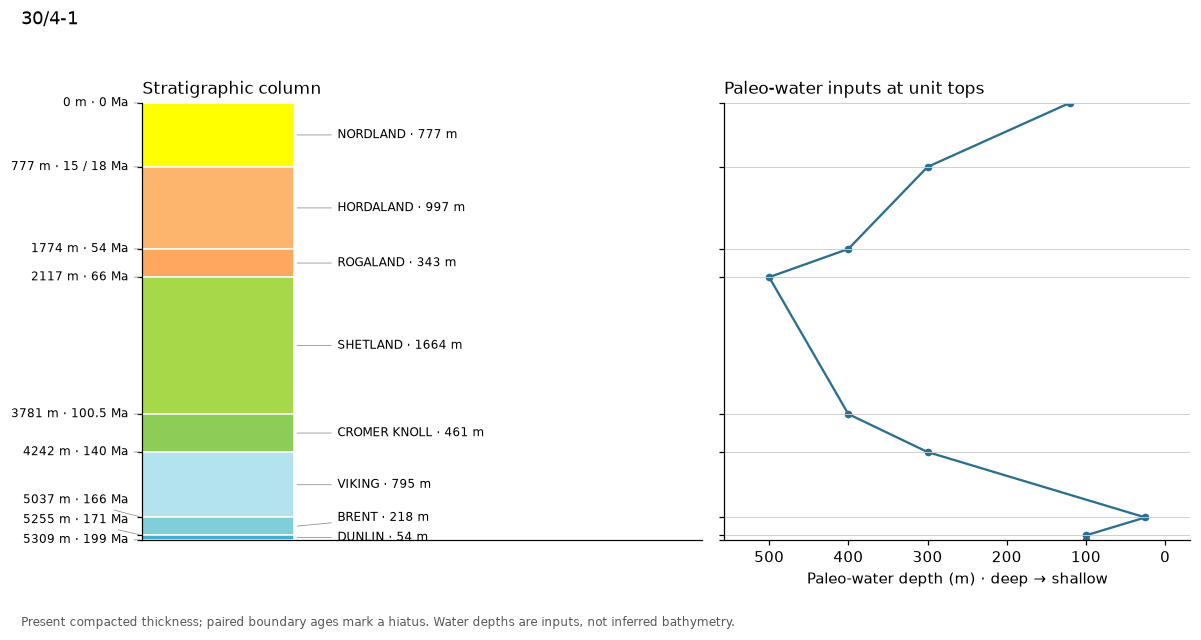

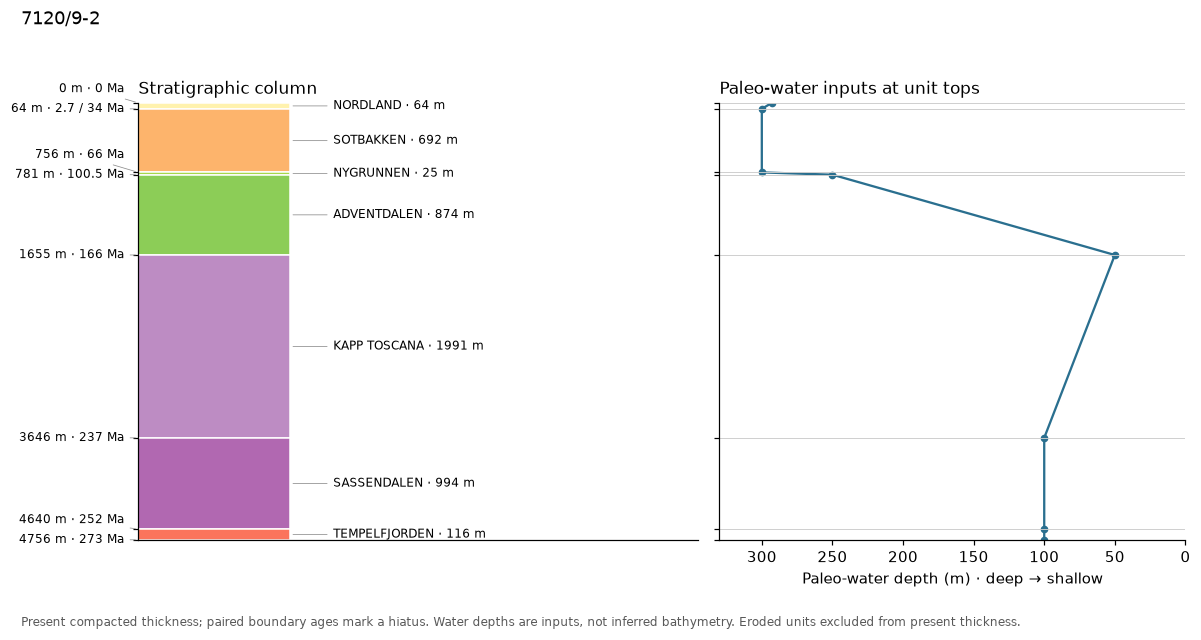

In [3]:
%matplotlib inline
from pybasinsubs.input_plots import stratigraphic_column, compaction_relations, interpreted_section
from IPython.display import display
import matplotlib.pyplot as plt
plt.ioff()
for w in ["30/4-1", "7120/9-2"]:
    fig = stratigraphic_column(R[w].column)
    display(fig); plt.close(fig)


## 2 · Compaction relations used

These wells contain tops, ages and lithology assumptions, not measured porosity logs. Only the actual model curves are plotted.

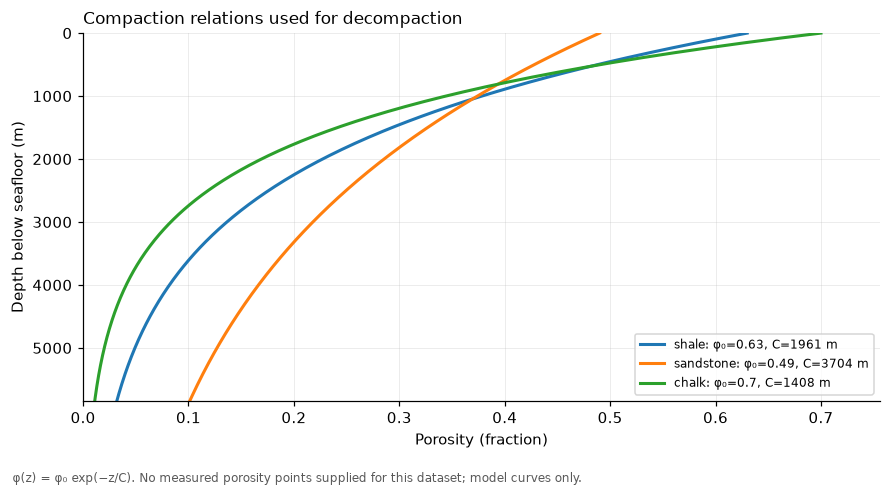

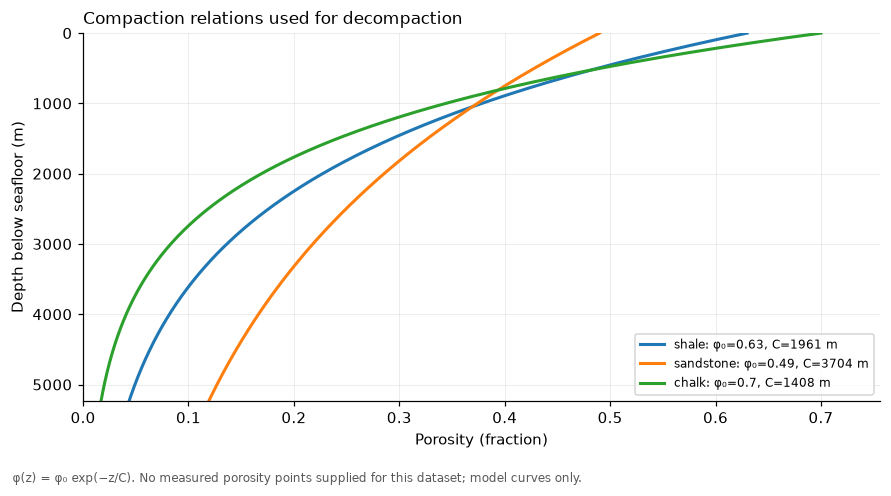

In [4]:
for w in ["30/4-1", "7120/9-2"]:
    fig = compaction_relations(R[w].column)
    display(fig); plt.close(fig)


## 3 · Geohistory and tables

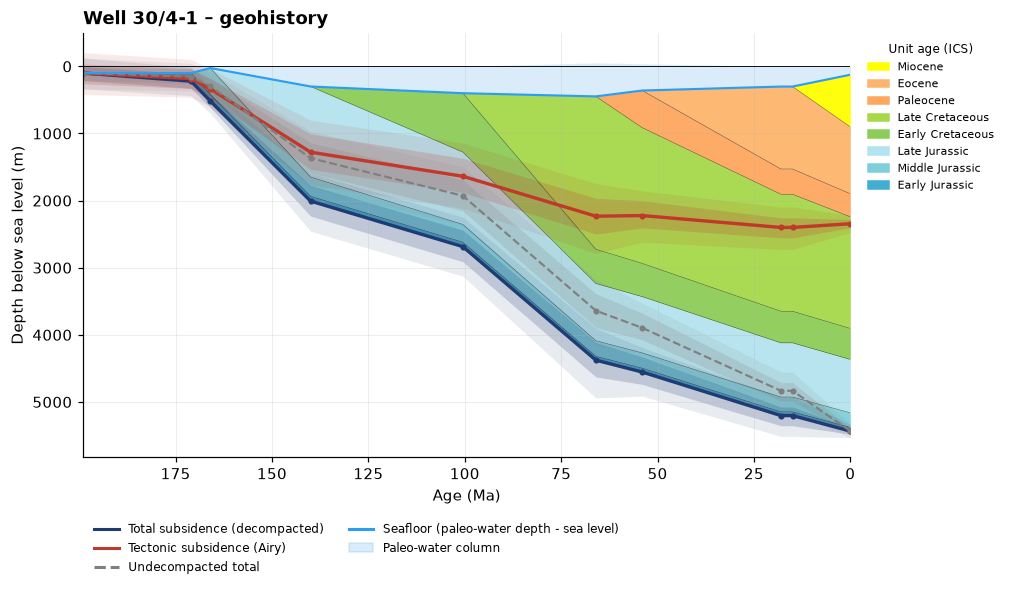

,node,age_Ma,undecompacted_total_m,undecompacted_total_m_sd,undecompacted_total_m_p2.5,undecompacted_total_m_p16,undecompacted_total_m_p50,undecompacted_total_m_p84,undecompacted_total_m_p97.5,total_subsidence_m,...,water_depth_m_p84,water_depth_m_p97.5,sea_level_m,sea_level_m_sd,sea_level_m_p2.5,sea_level_m_p16,sea_level_m_p50,sea_level_m_p84,sea_level_m_p97.5,age_Ma_sd
0,base (TD),199.0,100.00,113.24,-124.41,4.62,101.41,211.40,335.77,100.00,...,149.19,186.92,0.00,104.04,-204.29,-104.87,-6.59,94.83,216.30,2.00
1,DUNLIN,171.0,154.00,107.59,-47.99,42.96,155.91,255.06,366.74,220.30,...,146.46,192.78,0.00,97.86,-188.87,-99.36,0.18,94.23,196.95,1.93
2,BRENT,166.0,297.00,100.10,83.95,187.86,298.55,393.21,473.56,516.14,...,47.88,72.42,0.00,97.71,-171.47,-96.49,2.58,110.52,203.52,1.48
3,VIKING,140.0,1367.00,220.52,968.87,1136.26,1357.07,1586.80,1807.50,2007.04,...,483.91,705.07,0.00,100.71,-197.46,-95.82,1.15,106.37,194.30,1.92
4,CROMER KNOLL,100.5,1928.00,225.10,1498.66,1692.73,1924.43,2151.54,2369.00,2685.72,...,590.43,784.17,0.00,100.79,-194.85,-97.34,0.79,99.04,196.84,0.99
5,SHETLAND,66.0,3639.82,255.26,3170.53,3388.08,3643.02,3890.06,4149.92,4377.14,...,759.90,1024.78,52.18,1.11,50.19,51.14,52.21,53.40,54.39,0.53
6,ROGALAND,54.0,3895.20,195.38,3526.80,3675.57,3880.38,4075.08,4286.40,4553.78,...,587.77,771.54,39.80,1.99,36.10,37.80,39.88,41.82,43.59,1.02
7,HORDALAND,18.0,4833.05,146.47,4551.66,4711.08,4853.06,4986.74,5138.55,5202.85,...,450.63,603.50,-1.05,0.69,-2.45,-1.74,-1.04,-0.39,0.26,1.98
8,start of NORDLAND,15.0,4833.05,146.47,4551.66,4711.08,4853.06,4986.74,5138.55,5202.85,...,450.63,603.50,-1.05,0.69,-2.45,-1.74,-1.04,-0.39,0.26,0.00
9,NORDLAND,0.0,5433.89,47.50,5332.89,5385.67,5434.08,5479.79,5530.61,5433.89,...,130.17,137.97,-4.39,2.55,-9.11,-6.95,-4.40,-1.62,0.49,0.00


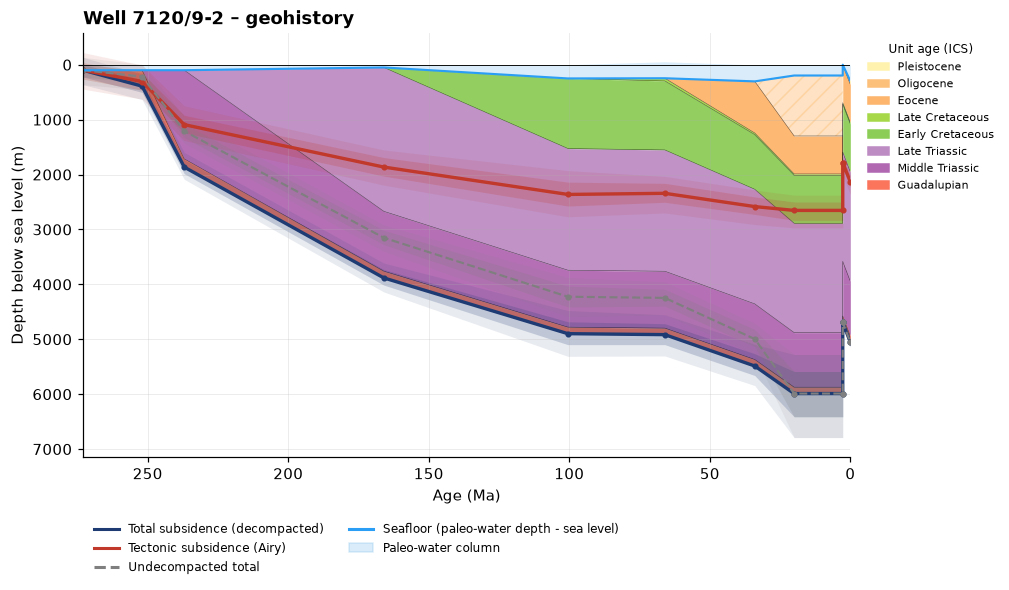

,node,age_Ma,undecompacted_total_m,undecompacted_total_m_sd,undecompacted_total_m_p2.5,undecompacted_total_m_p16,undecompacted_total_m_p50,undecompacted_total_m_p84,undecompacted_total_m_p97.5,total_subsidence_m,...,water_depth_m_p84,water_depth_m_p97.5,sea_level_m,sea_level_m_sd,sea_level_m_p2.5,sea_level_m_p16,sea_level_m_p50,sea_level_m_p84,sea_level_m_p97.5,age_Ma_sd
0,base (TD),273.0,100.00,122.05,-134.67,-5.88,106.59,223.10,364.55,100.00,...,173.79,230.38,0.00,104.04,-204.29,-104.87,-6.59,94.83,216.30,2.00
1,TEMPELFJORDEN,252.0,216.00,116.87,-6.85,103.49,218.59,329.30,455.80,390.40,...,169.69,239.17,0.00,97.86,-188.87,-99.36,0.18,94.23,196.95,1.95
2,SASSENDALEN,237.0,1210.00,120.55,942.92,1080.46,1213.84,1326.57,1426.32,1864.22,...,168.65,242.27,0.00,97.71,-171.47,-96.49,2.58,110.52,203.52,1.97
3,KAPP TOSCANA,166.0,3151.00,123.20,2918.64,3016.32,3141.46,3274.41,3397.34,3882.42,...,95.98,151.27,0.00,100.71,-197.46,-95.82,1.15,106.37,194.30,1.92
4,ADVENTDALEN,100.5,4225.00,187.17,3874.65,4035.43,4227.71,4410.11,4587.47,4897.78,...,392.82,538.13,0.00,100.79,-194.85,-97.34,0.79,99.04,196.84,0.99
5,NYGRUNNEN,66.0,4246.40,157.37,3955.73,4090.78,4245.90,4394.97,4555.38,4915.54,...,455.94,614.87,53.60,0.91,51.97,52.74,53.62,54.60,55.41,1.05
6,SOTBAKKEN,34.0,4995.62,150.28,4710.53,4824.94,4987.10,5132.25,5271.96,5486.73,...,440.83,578.66,-3.62,0.59,-4.73,-4.22,-3.60,-3.02,-2.49,3.03
7,ERODED CENOZOIC,20.0,5988.62,400.56,5277.85,5586.73,6009.01,6410.74,6790.16,5988.62,...,300.42,402.33,3.38,0.44,2.48,2.94,3.39,3.81,4.23,4.94
8,before erosion of ERODED CENOZOIC,2.7,5988.62,400.56,5277.85,5586.73,6009.01,6410.74,6790.16,5988.62,...,300.42,402.33,3.38,0.44,2.48,2.94,3.39,3.81,4.23,0.00
9,erosion of ERODED CENOZOIC,2.7,4692.00,49.40,4590.30,4638.71,4687.68,4738.65,4782.03,4692.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


In [5]:
for w, tag in [("30/4-1", "viking"), ("7120/9-2", "barents")]:
    fig, ax = plt.subplots(figsize=(9, 5)); geohistory(R[w], ax=ax, title=f"Well {w} – geohistory")
    display(fig); plt.close(fig)
    display(R[w].summary().round(2))

**Reading.** *30/4-1 (Viking Graben)*: fast Jurassic subsidence (rifting), then a long, slowing Cretaceous–Cenozoic subsidence — thermal cooling after rifting. *7120/9-2 (Hammerfest Basin)*: the hatched band is ~1 km of Cenozoic sediment that was later **eroded** (Barents uplift, here placed at 2.7 Ma). When it is stripped off, the column rebounds upward: the red tectonic curve jumps up at the right edge.

## 4 · Thermal history and tables

First check the temperature/heat-flow constraints, then burial temperature and maturity.

### Present-day temperature: BHT, IHFC heat flow and the model

In [6]:
ihfc = pd.read_csv(data_path("heatflow", "ihfc2024_northsea_barents.csv"))
ihfc = ihfc[(ihfc.q > 0) & (ihfc.q < 250)]   # drop flagged/negative entries
print(ihfc.columns.tolist()[:12])
latc = [c for c in ihfc.columns if c.lower().startswith("lat")][0]; lonc = [c for c in ihfc.columns if c.lower().startswith("lon")][0]
qc = [c for c in ihfc.columns if c.lower() in ("q", "q_mw", "heat_flow", "heatflow_mw_m2", "q_mwm2")] or [c for c in ihfc.columns if "q" in c.lower()]
qc = qc[0]; print("heat-flow column:", qc)
def nearest_q(lat, lon, k=5):
    d = np.hypot(ihfc[latc] - lat, (ihfc[lonc] - lon) * np.cos(np.radians(lat))) * 111
    i = np.argsort(d.to_numpy())[:k]
    return ihfc[qc].iloc[i].median(), d.iloc[i].median()
rows = []
for df in (VG, BA):
    for _, w in df.iterrows():
        z = w.td_md_m - w.kb_m - w.water_depth_m
        Tc, tsc_used, tsc_assumed = thermal.bht_correct(w.bht_degC, z, w.get("tsc_h", np.nan))   # per-measurement t_sc, 12 h if missing
        Tc = float(Tc[0])
        r = R[w.well]; zg, phi, k, _ = thermal.column_profile(r)
        q = thermal.heat_flow_from_temperature(Tc, z, zg, k)
        qn, dn = nearest_q(w.lat, w.lon)
        rows.append(dict(well=w.well, depth_bsf_m=z, BHT=w.bht_degC, tsc_h=tsc_used[0], tsc_assumed=bool(tsc_assumed[0]), T_corr=Tc, q_from_BHT=q * 1e3, q_IHFC_near=qn, dist_km=dn))
hf = pd.DataFrame(rows).set_index("well"); hf.round(1)

['name', 'lat', 'lon', 'elevation', 'environment', 'q', 'q_uncertainty', 'total_depth_MD', 'total_depth_TVD', 'explo_method', 'q_method', 'T_grad_mean']
heat-flow column: q


,depth_bsf_m,BHT,tsc_h,tsc_assumed,T_corr,q_from_BHT,q_IHFC_near,dist_km
well,,,,,,,,
29/6-1,4683.3,166.0,12.0,True,204.7,67.7,50.0,188.4
30/4-1,5309.2,161.0,12.0,True,196.7,58.8,50.0,180.6
30/5-2,3958.0,139.0,12.0,True,173.4,65.7,50.0,180.1
30/6-1,3044.0,91.0,12.0,True,115.3,52.9,50.0,177.7
30/6-5,3369.0,126.0,12.0,True,158.9,67.7,50.0,168.2
31/4-3,4786.0,143.0,12.0,True,175.9,57.8,50.0,179.7
31/5-2,2158.0,87.0,12.0,True,113.0,67.4,44.0,154.7
31/6-1,3743.0,132.0,12.0,True,165.3,65.7,44.0,147.4
7119/12-3,3074.0,136.0,12.0,True,172.8,87.6,65.0,184.6


saved image/nb6_heatflow_bht_vs_ihfc.png


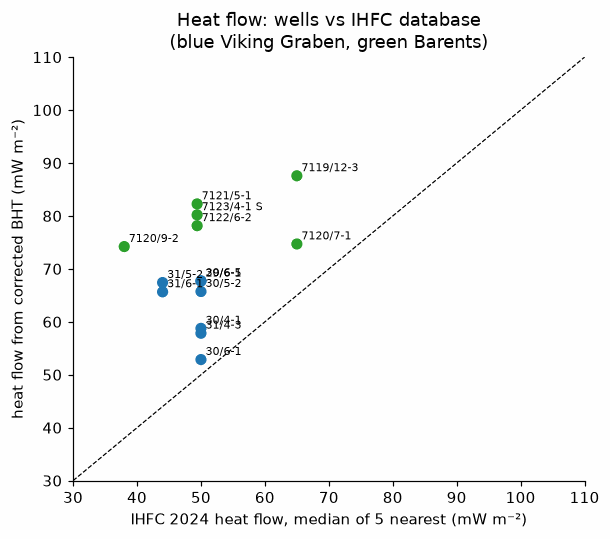

In [7]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(hf.q_IHFC_near, hf.q_from_BHT, c=["#1f77b4" if w in set(VG.well) else "#2ca02c" for w in hf.index], s=40)
for w, rr in hf.iterrows(): ax.annotate(w, (rr.q_IHFC_near, rr.q_from_BHT), fontsize=7, xytext=(3, 3), textcoords="offset points")
lim = [30, 110]; ax.plot(lim, lim, "k--", lw=.8); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("IHFC 2024 heat flow, median of 5 nearest (mW m⁻²)"); ax.set_ylabel("heat flow from corrected BHT (mW m⁻²)")
ax.set_title("Heat flow: wells vs IHFC database\n(blue Viking Graben, green Barents)")
save(fig, "nb6_heatflow_bht_vs_ihfc.png"); plt.show()

**Reading.** Points on the dashed line mean the heat flow implied by the corrected bottom-hole temperature and our compaction-dependent conductivity agrees with nearby measured heat flow. The BHT-derived values are ~5–35 mW m⁻² higher than the database here. Two reasons: BHT corrections are crude (circulation time unknown, 12 h assumed), and the nearest IHFC points are **~150–200 km away** (none fall inside the transect windows), so this is a plausibility check, not a validation.

### Burial temperature and maturity (Easy%Ro)

saved image/nb6_maturity_viking_30-4-1.png


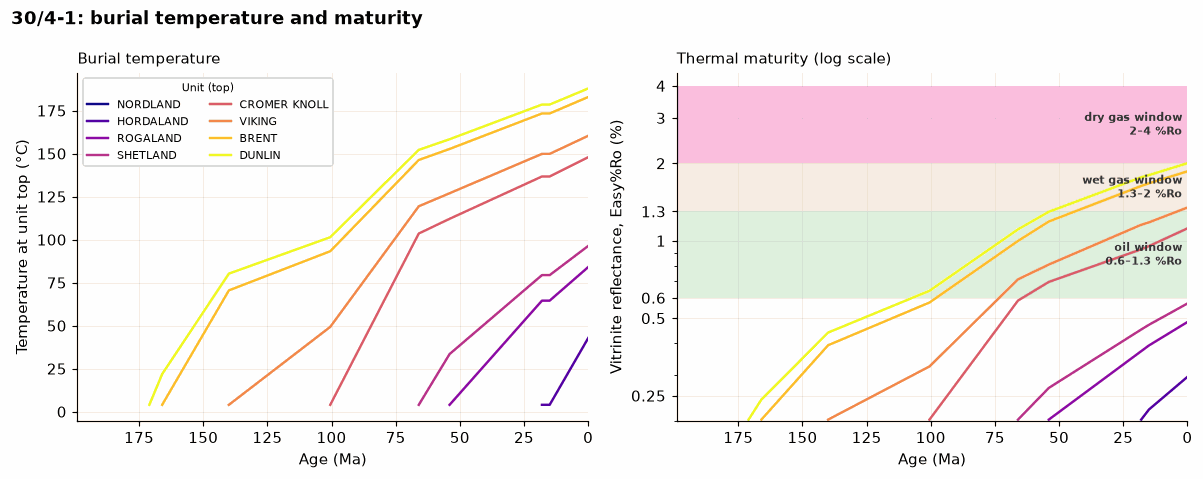

,unit,present_T_C,present_Ro,window
0,NORDLAND,4.00,NaN,
1,HORDALAND,42.73,0.30,immature
2,ROGALAND,84.01,0.48,immature
3,SHETLAND,96.30,0.57,immature
4,CROMER KNOLL,147.87,1.12,oil
5,VIKING,160.33,1.35,wet gas
6,BRENT,182.86,1.86,wet gas
7,DUNLIN,187.83,2.00,dry gas


saved image/nb6_maturity_barents_7120-9-2.png


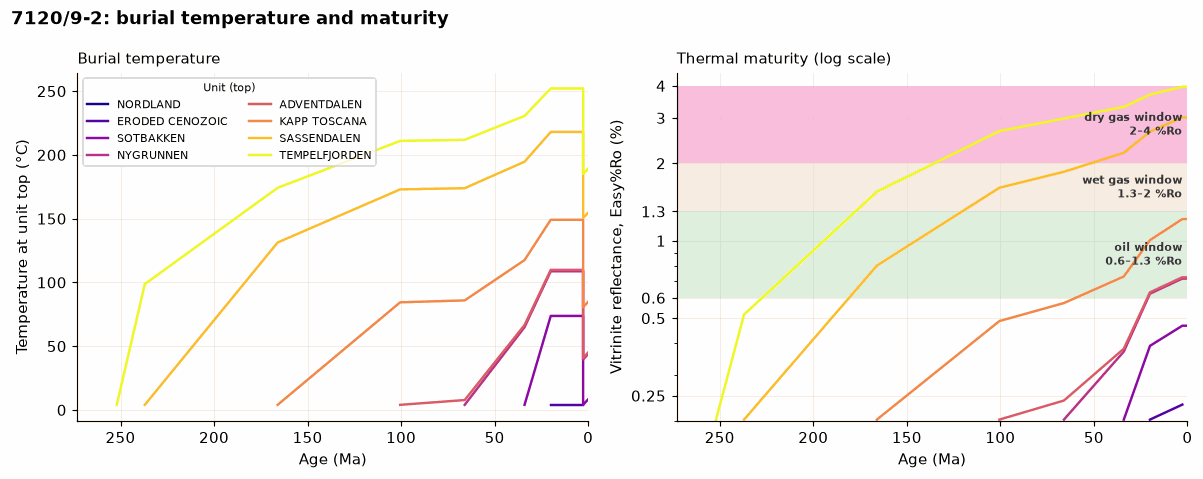

,unit,present_T_C,present_Ro,window
0,NORDLAND,4.00,NaN,
1,ERODED CENOZOIC,NaN,NaN,
2,SOTBAKKEN,8.32,0.47,immature
3,NYGRUNNEN,43.85,0.71,oil
4,ADVENTDALEN,45.02,0.72,oil
5,KAPP TOSCANA,84.82,1.21,oil
6,SASSENDALEN,154.67,3.02,dry gas
7,TEMPELFJORDEN,189.28,3.97,dry gas


In [8]:
for w, tag in [("30/4-1", "viking"), ("7120/9-2", "barents")]:
    q = hf.loc[w, "q_from_BHT"] / 1e3
    bt = thermal.burial_temperatures(R[w], heat_flow=q, T_s=4.0)
    from pybasinsubs.app_core import maturity_figure
    fig, tab = maturity_figure(R[w], bt)
    save(fig, f"nb6_maturity_{tag}_{w.replace('/', '-')}.png"); plt.show(); display(tab.round(2))

**Reading.** The right panel uses a log %Ro axis with plain tick values (0.5, 0.6, 1.3, 2 …) and the windows labelled at the right edge. Left: temperature of each unit's top through time (it warms as it is buried). Right: vitrinite reflectance from Easy%Ro, with the oil window (0.6–1.3 %Ro, green band) and gas windows above. A unit crossing 0.6 %Ro is when its source rock started generating oil. For **30/4-1** (heat flow 59 mW m⁻² from the corrected BHT), the Upper Jurassic Viking Group — which contains the Draupne source rock — enters the oil window at ~55 Ma and is near the oil/wet-gas boundary today (~1.3 %Ro); the deeper Brent and Dunlin groups are in the wet-gas window. For **7120/9-2**, temperatures and %Ro rise until ~2.7 Ma and then temperatures drop when ~1 km of Cenozoic section is eroded, so maturation essentially stops. Because the present-day BHT heat flow (74 mW m⁻²) is applied for the whole history, the Triassic units come out over-mature (dry gas); treat that as an upper bound.

Constant present-day heat flow is a simplification; `thermal.burial_temperatures(r, heat_flow=lambda age: ...)` accepts a McKenzie heat-flow history (`thermal.mckenzie_heat_flow`) and `method="transient"`.

### Burial diagram with isotherms and maturity windows

**What.** The same geohistory as above (depth below sea level, down, vs age; each unit coloured by its ICS age; light-blue = paleo-water column between paleo-sea level and paleo-seafloor), now with the thermal model drawn on top: thin red lines are **isotherms** every 25 °C, and thick dashed lines are where **Easy%Ro** reaches 0.6 % (oil window top, green), 1.3 % (wet gas, orange) and 2.0 % (dry gas, magenta).

**How.** At each backstrip time step the column's geotherm is computed with porosity-dependent conductivity and the same heat flow as above (from the corrected BHT, constant in time):

$$T(z,t)=T_s+\int_0^{z}\frac{q_s-A z'}{k(z',t)}\,dz',\qquad k=k_m^{1-\phi(z,t)}\,k_w^{\phi(z,t)},\qquad \phi=\phi_0e^{-z/C}$$

and placed below the paleo-seafloor $W(t)-\Delta SL(t)$. Geotherms are interpolated between time steps (1 Myr grid). Four tracer points inside every unit follow their decompacted burial path; Easy%Ro is integrated along each path (Sweeney & Burnham 1990: $\%R_o=\exp(-1.6+3.7F)$, $dx_i/dt=-A e^{-E_i/RT}x_i$) and contoured.

Symbols: $T_s$ = seafloor temperature (4 °C), $q_s$ = surface heat flow, $A$ = radiogenic heat production (1 µW m⁻³), $k_m,k_w$ = matrix / water conductivity, $\phi$ porosity, $W$ paleo-water depth, $\Delta SL$ eustatic sea level, $F$ converted kinetic fraction.

saved image/nb6_burial_isotherms_viking_30-4-1.png


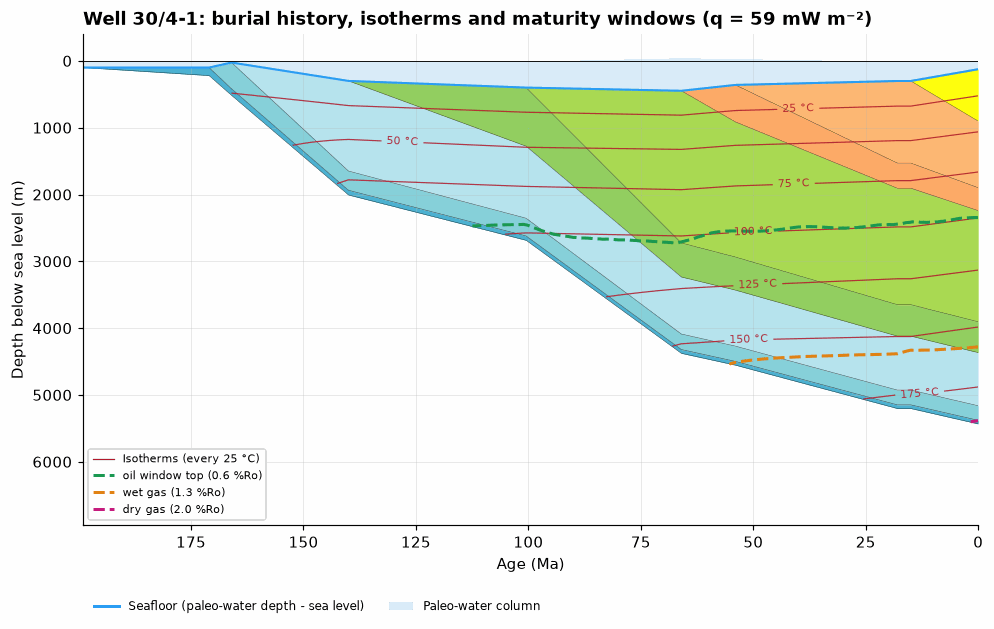

saved image/nb6_burial_isotherms_barents_7120-9-2.png


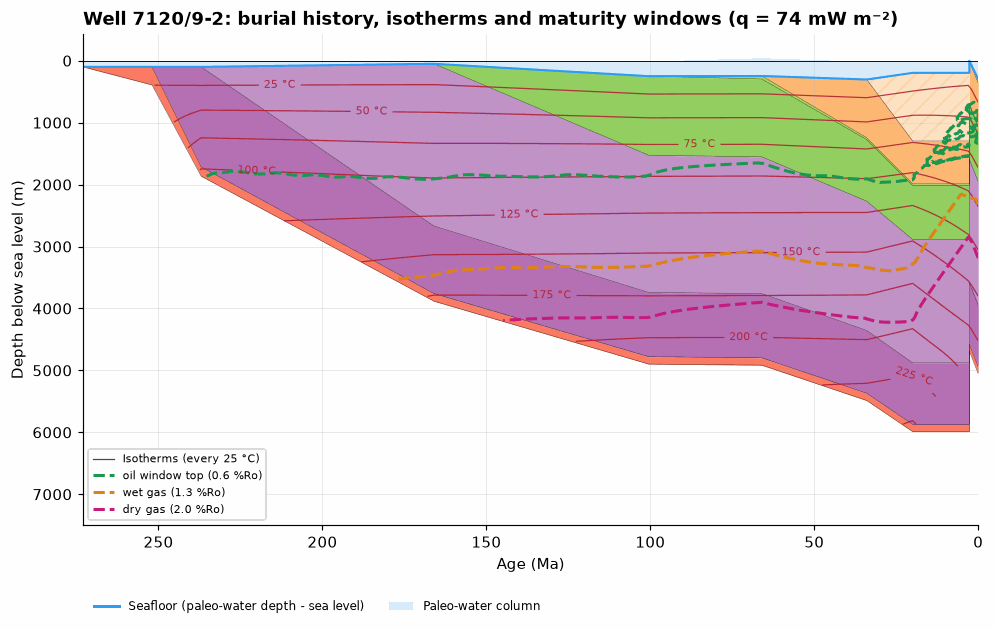

In [9]:
from pybasinsubs.plotting import geohistory_thermal
for w, tag in [("30/4-1", "viking"), ("7120/9-2", "barents")]:
    q = hf.loc[w, "q_from_BHT"] / 1e3
    tf = thermal.temperature_field(R[w], heat_flow=q, T_s=4.0)
    mf = thermal.maturity_field(R[w], tf)
    fig, ax = plt.subplots(figsize=(10.5, 5.8))
    geohistory_thermal(R[w], tf, mf, ax=ax, title=f"Well {w}: burial history, isotherms and maturity windows (q = {q*1e3:.0f} mW m⁻²)")
    save(fig, f"nb6_burial_isotherms_{tag}_{w.replace('/', '-')}.png"); plt.show()

**Reading.** Isotherms run almost flat because temperature mostly depends on depth; where they bend down, sediment was added fast and the column is thicker. A unit's band crossing an isotherm tells you when it reached that temperature. Units below the green dashed line had generated oil by that time; below the orange line they were in the wet-gas window. For **30/4-1** the 0.6 %Ro line sits near 2.4–2.6 km and the Viking Group (with the Draupne source rock) crosses it in the Late Cretaceous–Paleogene; the Brent/Dunlin base is below the 1.3 % line today. For **7120/9-2** the hatched band is the eroded Cenozoic section; after uplift the isotherms rise relative to the strata, so maturation stops.

**Caveats.** Heat flow is today's BHT-derived value held constant (no McKenzie syn-rift heat pulse); lithology fractions, paleo-water depths and erosion amounts in the Sodir columns are generic group-level estimates, not well-specific measurements. Read the lines as a consistent model, not a calibrated basin model (no vitrinite data were fitted).

### Optional 1-D timestep views and animations (original figures above are unchanged)

A separate, thin numbered stratigraphic column follows the **exact backstripping constraint nodes**, oldest at left and youngest at right. Water occupies −SL to W−SL only when W > 0; depth below present sea level is positive down. The column and geothermal strip share a fixed depth range over the entire history. The oldest node is an empty paleo surface; younger nodes add the remaining decompacted units. Hiatus and pre/post-erosion events are retained as separate nodes.

The geothermal strip uses the same porosity-dependent conductivity and heat-flow model as the existing thermal functions. Colored oil/gas bands are **kinetic Easy%Ro windows from material tracers**, not temperature thresholds; they stop at the range sampled by sediment tracers. Heat flow is specified in **W/m²** (0.059 = 59 mW/m²). Unit numbers refer to the input unit order (1-based).

The two dedicated GIF functions work with the inline notebook backend. `timestep_view(r)` or `timestep_view(r, thermal_view=True, fields=fields)` returns a Matplotlib figure and a true age-proportional, node-snapping slider when an interactive Matplotlib backend is available; Left/Right keys also traverse equal-age erosion events. No change to `geohistory`, `geohistory_thermal`, or `maturity_plot` is required.


In [ ]:
from pathlib import Path
from IPython.display import Image as DisplayImage
from pybasinsubs import (
    timestep_steps, timestep_column, timestep_thermal_fields, timestep_view,
    plot_geohistory_timestep, plot_thermal_timestep,
    save_geohistory_animation, save_thermal_animation,
)
r = R["30/4-1"]
fields = timestep_thermal_fields(r, heat_flow=0.059, T_s=4.0)
timestep_output = Path(IMG) / "timestep_1d"
timestep_output.mkdir(exist_ok=True)
steps = timestep_steps(r)
# All figures keep the original static figures above intact.
fig = plot_geohistory_timestep(r, step=-1)
display(fig); plt.close(fig)
fig = plot_thermal_timestep(r, step=-1, fields=fields)
display(fig); plt.close(fig)
for step in [0, len(steps) // 2, len(steps) - 1]:
    fig = plot_thermal_timestep(r, step=step, fields=fields, column_only=True)
    fig.savefig(timestep_output / f"column_geotherm_{step:02d}.png", dpi=120)
    plt.close(fig)
geo_gif = save_geohistory_animation(r, timestep_output / "geohistory_history.gif", fps=1)
thermal_gif = save_thermal_animation(r, timestep_output / "thermal_history.gif", fields=fields, fps=1)
display(DisplayImage(filename=str(geo_gif)))
display(DisplayImage(filename=str(thermal_gif)))
# With an interactive backend, instead of an inline-only backend:
# fig, age_slider = timestep_view(r, thermal_view=True, fields=fields)
# plt.show()


#### Linked burial temperature and maturity view

The familiar two-panel layout keeps the **full** curves, with an age guide and white-fill unit markers. Its blue unit colors match **unit-top** horizons in the thermal geohistory. Oil/gas windows remain kinetic Easy%Ro. The geotherm always includes a clearly labeled window-color **key**; key swatches are not claimed depth intervals where no sediment tracers support a window (including the empty oldest step).

Use `slider=False` on the column/geotherm figures for a shared selector above a stacked view; standalone plot/GIF defaults retain their painted age track. Equal-age erosion events share the same two-panel overlay, while the column differs. GIF footers identify every exact event.


In [ ]:
from pybasinsubs import maturity_timestep_data, plot_maturity_timestep, save_maturity_animation
r = R["30/4-1"]
# Reuse a burial_temperatures dict with burial=... if already available.
unit_history = maturity_timestep_data(r, heat_flow=0.059, T_s=4.0)
fig = plot_maturity_timestep(r, step=5, data=unit_history)
display(fig); plt.close(fig)
maturity_gif = save_maturity_animation(r, timestep_output / "maturity_history.gif", data=unit_history, fps=1)
display(DisplayImage(filename=str(maturity_gif)))


## Additional diagnostics · McKenzie fit

### McKenzie fit

In [4]:
rift_end = 140.0
fits = []
for w, r in R.items():
    s = r.summary().sort_values("age_Ma", ascending=False)
    if w in set(BA.well):          # fit only before the late-Cenozoic uplift/erosion (2.7 Ma)
        s = s[s.age_Ma > 2.7 + 1e-6]
    b, rms = thermal.fit_beta(s.age_Ma.to_numpy(), s.tectonic_subsidence_m.to_numpy(), rift_end)
    fits.append(dict(well=w, transect="Viking" if w in set(VG.well) else "Barents", beta=b, rms_m=rms))
fits = pd.DataFrame(fits).set_index("well"); fits.round(2)

,transect,beta,rms_m
well,,,
29/6-1,Viking,1.34,210.69
30/4-1,Viking,1.42,110.71
30/5-2,Viking,1.37,236.01
30/6-1,Viking,1.15,168.07
30/6-5,Viking,1.17,114.27
31/4-3,Viking,1.08,70.28
31/5-2,Viking,1.09,67.81
31/6-1,Viking,1.06,17.68
7119/12-3,Barents,1.48,94.29


β is the stretching factor that best explains post-rift tectonic subsidence (rms = misfit). Barents wells are fitted only up to the 2.7 Ma erosion, because uplift is not part of McKenzie's model. Values of 1.1–1.5 are in the range published for the northern North Sea.

saved image/nb6_mckenzie_fit_30-4-1.png


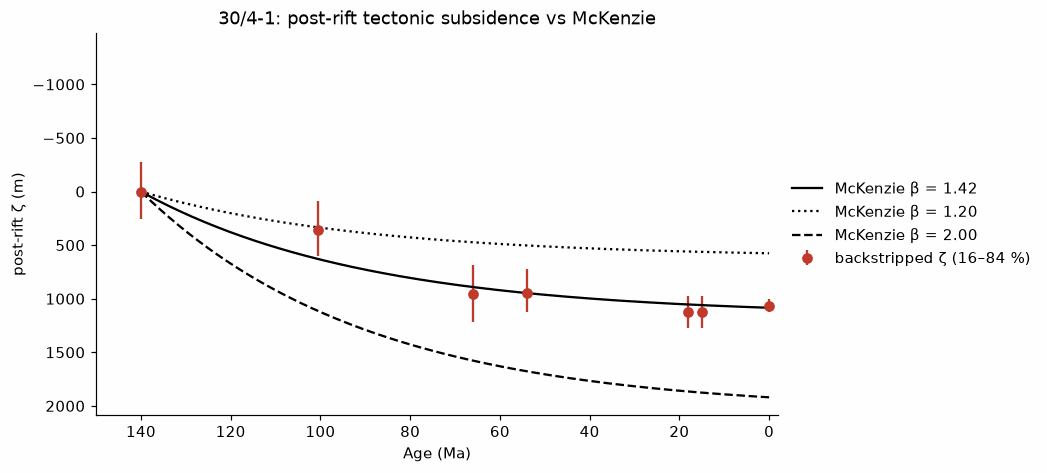

In [5]:
w = "30/4-1"; s = R[w].summary().sort_values("age_Ma", ascending=False)
z0 = np.interp(rift_end, s.age_Ma[::-1], s.tectonic_subsidence_m[::-1])
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(s.age_Ma, s.tectonic_subsidence_m - z0, yerr=[s.tectonic_subsidence_m - s["tectonic_subsidence_m_p16"], s["tectonic_subsidence_m_p84"] - s.tectonic_subsidence_m], fmt="o", color="#c0392b", label="backstripped ζ (16–84 %)")
t = np.linspace(0, rift_end, 200)
for b, ls in [(fits.loc[w, "beta"], "-"), (1.2, ":"), (2.0, "--")]:
    ax.plot(rift_end - t, thermal.mckenzie_postrift(t, b), ls, color="k", label=f"McKenzie β = {b:.2f}")
ax.set_xlim(rift_end + 10, -2); ax.invert_yaxis(); ax.set_xlabel("Age (Ma)"); ax.set_ylabel("post-rift ζ (m)")
ax.set_title(f"{w}: post-rift tectonic subsidence vs McKenzie"); ax.legend(loc="center left", bbox_to_anchor=(1, .5), frameon=False)
save(fig, "nb6_mckenzie_fit_30-4-1.png"); plt.show()

**Reading.** Red points: tectonic subsidence since the end of rifting. Solid line: McKenzie curve with the best β. If points follow the curve, post-rift subsidence is explained by cooling of a lithosphere stretched by that β. The dotted/dashed curves for β = 1.2 and 2.0 bracket it, showing how sensitive the shape is.

### Thermal benchmarks (analytic and published values vs the code)

The same checks run in `tests/test_thermal.py`:
1. **Steady geotherm** with uniform k, against the closed forms: constant A, $T=T_s+q_sz/k-Az^2/2k$; exponential A, $T=T_s+(q_s-A_0h_r)z/k+A_0h_r^2(1-e^{-z/h_r})/k$.
2. **McKenzie (1978)**, with McKenzie's parameters (ρ_m 3330, ρ_w 1000, κ 0.008 cm² s⁻¹):
   - E₀ ≈ 3.17 km and τ = 62.8 Myr;
   - the series limit $S_\infty=a\rho_m\alpha T_1(1-1/\beta)/[2(\rho_m-\rho_w)]$;
   - $q(0)=\beta\,kT_1/a$ and $q(\infty)=kT_1/a$.
3. **Easy%Ro (Sweeney & Burnham 1990).**
   - Published constants: 20 energies (34–72 kcal mol⁻¹), A = 10¹³ s⁻¹, Σf = 0.85, so %Ro runs from 0.20 to 4.69.
   - At constant heating rates, compared with the exact Arrhenius integral (numerical quadrature).
   - We could not find tabulated constant-rate %Ro values from the 1990 paper that we could verify, so this comparison is against the exact kinetics rather than against printed numbers.

,test,reference,pyBasinSubs,rel_diff_%
0,"steady geotherm, constant A: max |T - analytic...",0.0000,0.0000,NaN
1,"steady geotherm, A0 exp(-z/hr): max |T - analy...",0.0000,0.0000,NaN
2,"McKenzie E0 (m), McKenzie 1978 ≈ 3170",3170.0000,3165.6476,-0.1373
3,"McKenzie tau (Myr), McKenzie 1978 = 62.8",62.8000,62.7085,-0.1457
4,"post-rift S(inf), beta 2: series (m) vs closed...",1952.7306,1952.7306,-0.0000
5,"post-rift S(inf), beta 1.15: first term only (...",509.4080,461.6694,-9.3714
6,"heat flow q(0)/q_eq, beta 2 (= beta)",2.0000,1.9999,-0.0064
7,Easy%Ro initial / max %Ro (S&B 1990: 0.2 / ~4.7),4.7000,4.6880,-0.2559
8,"Easy%Ro at 200 °C, 1 °C/Myr: code vs exact int...",2.2297,2.2297,-0.0000
9,"Easy%Ro at 200 °C, 10 °C/Myr: code vs exact in...",1.7862,1.7862,-0.0001


saved image/nb6_thermal_benchmarks.png


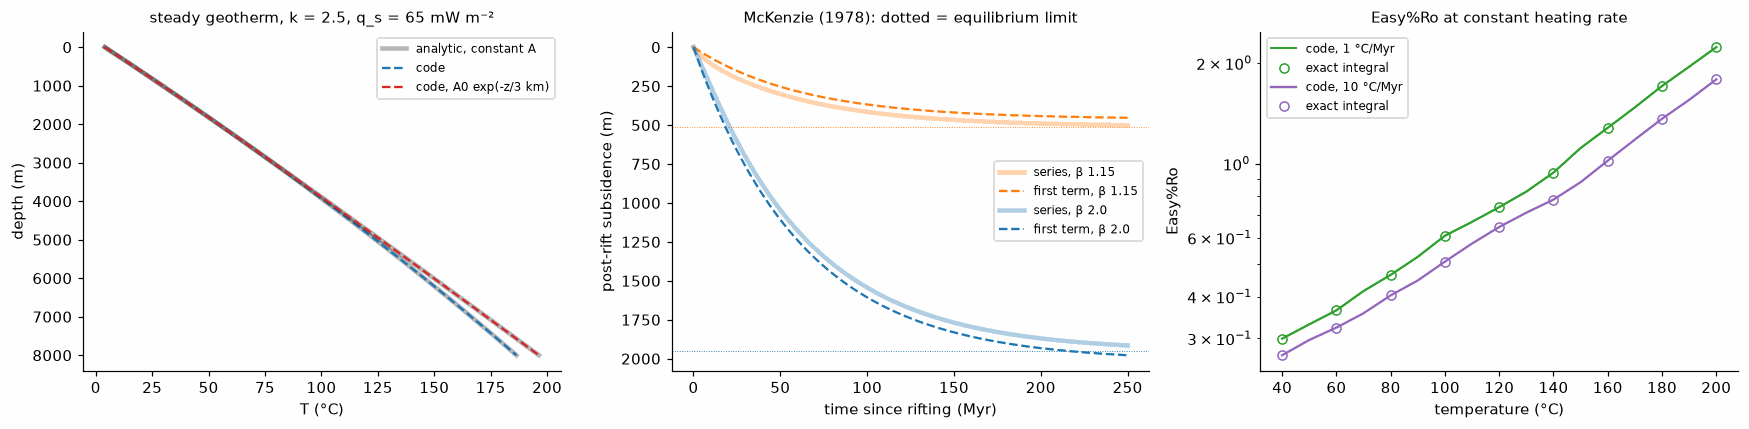

In [10]:
from scipy.integrate import quad
from pybasinsubs.constants import MCK
z = np.linspace(0, 8000, 801); kk = np.full_like(z, 2.5); qs = 0.065
T_c = thermal.steady_geotherm(z, kk, qs, 4.0, 2e-6); T_ca = 4 + qs * z / 2.5 - 2e-6 * z ** 2 / 5
T_e = thermal.steady_geotherm(z, kk, qs, 4.0, 2.5e-6, hr=3000.0); T_ea = 4 + (qs - 2.5e-6 * 3000) * z / 2.5 + 2.5e-6 * 3000 ** 2 * (1 - np.exp(-z / 3000)) / 2.5
P78 = dict(MCK, rho_m=3330.0, rho_w=1000.0, kappa=8e-7)
E0 = 4 * P78["a"] * 3330 * P78["alpha"] * P78["T1"] / (np.pi ** 2 * 2330); tau = P78["a"] ** 2 / (np.pi ** 2 * P78["kappa"]) / thermal.MYR
Sinf = lambda b: P78["a"] * 3330 * P78["alpha"] * P78["T1"] * (1 - 1 / b) / (2 * 2330)
K = thermal.EASY_RO
def ro_exact(rate, T0=20.0, T1=200.0):
    I = np.array([quad(lambda TK: np.exp(-E / (thermal.R_KCAL * TK)), T0 + 273.15, T1 + 273.15, epsrel=1e-10)[0] for E in K["E_kcal"]])
    return np.exp(-1.6 + 3.7 * np.sum(K["f"] * (1 - np.exp(-K["A"] / (rate / thermal.MYR) * I))))
def ro_code(rate, T0=20.0, T1=200.0):
    tt = np.linspace((T1 - T0) / rate, 0, 400); return thermal.easy_ro(tt, T0 + rate * (tt[0] - tt))[-1]
qeq = MCK["k"] * MCK["T1"] / MCK["a"]
BM = pd.DataFrame([
    ("steady geotherm, constant A: max |T - analytic| (°C)", 0.0, np.abs(T_c - T_ca).max()),
    ("steady geotherm, A0 exp(-z/hr): max |T - analytic| (°C)", 0.0, np.abs(T_e - T_ea).max()),
    ("McKenzie E0 (m), McKenzie 1978 ≈ 3170", 3170.0, E0),
    ("McKenzie tau (Myr), McKenzie 1978 = 62.8", 62.8, tau),
    ("post-rift S(inf), beta 2: series (m) vs closed form", Sinf(2.0), thermal.mckenzie_postrift(np.array([1e5]), 2.0, P78, nterms=500)[0]),
    ("post-rift S(inf), beta 1.15: first term only (m) vs closed form", Sinf(1.15), thermal.mckenzie_postrift(np.array([1e5]), 1.15, P78)[0]),
    ("heat flow q(0)/q_eq, beta 2 (= beta)", 2.0, thermal.mckenzie_heat_flow(np.array([0.0]), 2.0, nterms=5000)[0] / qeq),
    ("Easy%Ro initial / max %Ro (S&B 1990: 0.2 / ~4.7)", 4.7, np.exp(-1.6 + 3.7 * K["f"].sum())),
    ("Easy%Ro at 200 °C, 1 °C/Myr: code vs exact integral", ro_exact(1.0), ro_code(1.0)),
    ("Easy%Ro at 200 °C, 10 °C/Myr: code vs exact integral", ro_exact(10.0), ro_code(10.0)),
], columns=["test", "reference", "pyBasinSubs"])
BM["rel_diff_%"] = 100 * (BM.pyBasinSubs - BM.reference) / BM.reference.replace(0, np.nan)
display(BM.round(4))
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(T_ca, z, "k", lw=3, alpha=.3, label="analytic, constant A"); ax[0].plot(T_c, z, "C0--", label="code")
ax[0].plot(T_ea, z, "k", lw=3, alpha=.3); ax[0].plot(T_e, z, "C3--", label="code, A0 exp(-z/3 km)"); ax[0].invert_yaxis()
ax[0].set_xlabel("T (°C)"); ax[0].set_ylabel("depth (m)"); ax[0].legend(fontsize=8); ax[0].set_title("steady geotherm, k = 2.5, q_s = 65 mW m⁻²", fontsize=10)
t = np.linspace(0, 250, 200)
for b, c in [(1.15, "C1"), (2.0, "C0")]:
    ax[1].plot(t, thermal.mckenzie_postrift(t, b, P78, nterms=200), c, lw=3, alpha=.35, label=f"series, β {b}")
    ax[1].plot(t, thermal.mckenzie_postrift(t, b, P78), c + "--", label=f"first term, β {b}"); ax[1].axhline(Sinf(b), color=c, lw=.6, ls=":")
ax[1].invert_yaxis(); ax[1].set_xlabel("time since rifting (Myr)"); ax[1].set_ylabel("post-rift subsidence (m)"); ax[1].legend(fontsize=8)
ax[1].set_title("McKenzie (1978): dotted = equilibrium limit", fontsize=10)
TT = np.linspace(40, 200, 17)
for rate, c in [(1.0, "C2"), (10.0, "C4")]:
    ax[2].plot(TT, [ro_code(rate, 20.0, T_) for T_ in TT], c, label=f"code, {rate:g} °C/Myr")
    ax[2].plot(TT[::2], [ro_exact(rate, 20.0, T_) for T_ in TT[::2]], "o", color=c, mfc="none", label="exact integral")
ax[2].set_yscale("log"); ax[2].set_xlabel("temperature (°C)"); ax[2].set_ylabel("Easy%Ro"); ax[2].legend(fontsize=8)
ax[2].set_title("Easy%Ro at constant heating rate", fontsize=10)
fig.tight_layout(); save(fig, "nb6_thermal_benchmarks.png"); plt.show()

**Reading.**
- **Geotherms.** Both match the closed forms to a fraction of a degree.
- **McKenzie.** The constants reproduce McKenzie (1978).
- **Easy%Ro.** It follows the exact kinetic integral at both rates.

**One honest caveat.** The usual one-term McKenzie formula (used by `fit_beta` and by the 2-D reverse post-rift step) under-estimates the full series by ≈ 9–11 % at β ≈ 1.15–1.2 (462 vs 509 m equilibrium at β = 1.15; ≈ 5 % at β = 2). The β values fitted with it are therefore slightly too high. Pass `nterms=50` to `mckenzie_postrift` for the full series.

**BHT.** The time since circulation is now set per measurement. The Sodir files report none, so every value here is the 12 h default and is flagged `tsc_assumed=True` in the table above. For a 100 °C BHT at 3 km, 6 h or 18 h instead of 12 h changes the corrected value by +9 or −5 °C.

**Radiogenic heat.** `hr=` (e.g. 10 km for upper crust) switches A to $A_0e^{-z/h_r}$ in `steady_geotherm`, `burial_temperatures` and `temperature_field`.